In [1]:
import math, re, random
from datetime import datetime, timezone
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

matplotlib.rcParams['figure.dpi'] = 110
plt.style.use('seaborn-v0_8-darkgrid')
print("All imports successful — notebook is fully self-contained.")

All imports successful — notebook is fully self-contained.


In [2]:
# =============================================================
# INKER Query Analyzer  [B. INKER-Inspired Functionality]
# Source: inker/confidence.py
# =============================================================

class QueryAnalyzer:
    """Analyzes queries for complexity, entities, temporal, factual signals."""

    TEMPORAL_KEYWORDS = {
        "latest","recent","current","today","yesterday","now",
        "2024","2025","2026","updated","realtime","real-time","newest","status"
    }
    FACTUAL_KEYWORDS = {
        "what is","where is","who is","how much","inventory","return policy",
        "price","specification","manual","sales","revenue","order","stock",
        "details","list","compare"
    }

    @classmethod
    def estimate_complexity(cls, query: str) -> float:
        """E in [0,1] based on length, logical operators, punctuation."""
        words = query.strip().split()
        if not words: return 0.0
        length_score = min(len(words) / 25.0, 1.0)
        multi_clause = 0.3 if any(
            w in query.lower() for w in ["and","or","versus","vs","compare","if","while"]
        ) else 0.0
        punctuation = 0.2 if any(c in query for c in ["?",",",";",";"]) else 0.0
        return min(length_score * 0.5 + multi_clause + punctuation, 1.0)

    @classmethod
    def extract_entities(cls, query: str) -> list:
        quoted      = re.findall(r'"([^"]*)"', query)
        capitalized = re.findall(r'\b[A-Z][a-z0-9_]+\b', query)
        codes       = re.findall(r'\b[A-Za-z0-9]+-[0-9]+\b', query)
        return list(set(quoted + capitalized + codes))

    @classmethod
    def detect_temporal_need(cls, query: str) -> float:
        """Temporal sensitivity score in [0,1]."""
        words = set(query.lower().split())
        hits  = words.intersection(cls.TEMPORAL_KEYWORDS)
        return min(len(hits)*0.5 + (0.3 if any(c.isdigit() for c in query) else 0.0), 1.0)

    @classmethod
    def detect_factual_need(cls, query: str) -> float:
        """Factual lookup urgency in [0,1]."""
        q_lower, score = query.lower(), 0.0
        for kw in cls.FACTUAL_KEYWORDS:
            if kw in q_lower: score += 0.35
        return min(score, 1.0)


# ── Demo ──
demo_queries = [
    "What is 2 + 2?",
    "What is the current inventory stock of Product-42?",
    "Compare the latest sales revenue for Q1 2026 versus Q4 2025 and list the top 5 products.",
]
print(f"{'Query':<58} {'E':>6} {'Temporal':>10} {'Factual':>8}")
print("-" * 86)
for q in demo_queries:
    E = QueryAnalyzer.estimate_complexity(q)
    T = QueryAnalyzer.detect_temporal_need(q)
    F = QueryAnalyzer.detect_factual_need(q)
    print(f"{q[:56]:<58} {E:>6.3f} {T:>10.3f} {F:>8.3f}")

Query                                                           E   Temporal  Factual
--------------------------------------------------------------------------------------
What is 2 + 2?                                              0.300      0.300    0.350
What is the current inventory stock of Product-42?          0.660      0.800    1.000
Compare the latest sales revenue for Q1 2026 versus Q4 2    0.640      1.000    1.000


In [3]:
# =============================================================
# INKER IE-KRT  [B. INKER-Inspired Functionality]
# Source: inker/ie_krt.py
# =============================================================

class IEKRTResult:
    def __init__(self, retrieval_required, k_activation_score, confidence, reason, mode_used):
        self.retrieval_required = retrieval_required
        self.k_activation_score = k_activation_score
        self.confidence         = confidence
        self.reason             = reason
        self.mode_used          = mode_used
    def __repr__(self):
        icon = "YES — RETRIEVE" if self.retrieval_required else "NO  — skip retrieval"
        return (f"  Decision   : {icon}\n"
                f"  K score    : {self.k_activation_score:.4f}\n"
                f"  Confidence : {self.confidence:.4f}\n"
                f"  Mode       : {self.mode_used}\n"
                f"  Reason     : {self.reason}")

class IE_KRT:
    """Decides WHEN external retrieval is required.  [B]"""
    def __init__(self, activation_threshold=0.25):
        self.threshold = activation_threshold

    def evaluate(self, query, model_logits=None, forced_retrieval=None):
        if forced_retrieval is not None:
            return IEKRTResult(forced_retrieval, 1.0 if forced_retrieval else 0.0,
                               1.0, "Forced override", "manual")
        E            = QueryAnalyzer.estimate_complexity(query)
        factual_need = QueryAnalyzer.detect_factual_need(query)
        temporal_need= QueryAnalyzer.detect_temporal_need(query)
        if model_logits and "token_confidence" in model_logits:
            mode = "Mode A (Model-Confidence)"
            m_i  = float(model_logits["token_confidence"])
            S_i  = max(0.4, factual_need + temporal_need)
        else:
            mode = "Mode B (Query-Uncertainty Fallback)"
            m_i  = max(0.1, 1.0 - (0.5*factual_need + 0.4*temporal_need))
            S_i  = min(1.0, 0.3 + factual_need*0.4 + temporal_need*0.3)
        # Core INKER formula: K(t_i) = (E - m_i) * S_i
        raw_k        = (E - m_i) * S_i
        k_activation = max(raw_k, (factual_need + temporal_need) * 0.5)
        retrieval_required = k_activation >= self.threshold
        reason = (
            f"High external knowledge need (K={k_activation:.3f} >= theta={self.threshold:.3f})."
            if retrieval_required else
            f"Parametric memory sufficient (K={k_activation:.3f} < theta={self.threshold:.3f}).")
        return IEKRTResult(retrieval_required, round(k_activation,4),
                           round(1.0-m_i,4), reason, mode)

krt = IE_KRT(activation_threshold=0.25)
test_cases = [
    ("What is 2 + 2?",                                     None),
    ("What is the current inventory of Product-42?",       None),
    ("Compare latest Q1 2026 revenue vs Q4 2025.",         None),
    ("Return policy?",                  {"token_confidence": 0.9}),
    ("Stock of Widget-99?",             {"token_confidence": 0.3}),
]
for query, logits in test_cases:
    r = krt.evaluate(query, model_logits=logits)
    print(f'\nQuery: "{query}"')
    print(r)


Query: "What is 2 + 2?"
  Decision   : YES — RETRIEVE
  K score    : 0.3250
  Confidence : 0.2950
  Mode       : Mode B (Query-Uncertainty Fallback)
  Reason     : High external knowledge need (K=0.325 >= theta=0.250).

Query: "What is the current inventory of Product-42?"
  Decision   : YES — RETRIEVE
  K score    : 0.7500
  Confidence : 0.6700
  Mode       : Mode B (Query-Uncertainty Fallback)
  Reason     : High external knowledge need (K=0.750 >= theta=0.250).

Query: "Compare latest Q1 2026 revenue vs Q4 2025."
  Decision   : YES — RETRIEVE
  K score    : 0.8500
  Confidence : 0.7500
  Mode       : Mode B (Query-Uncertainty Fallback)
  Reason     : High external knowledge need (K=0.850 >= theta=0.250).

Query: "Return policy?"
  Decision   : NO  — skip retrieval
  K score    : 0.1750
  Confidence : 0.1000
  Mode       : Mode A (Model-Confidence)
  Reason     : Parametric memory sufficient (K=0.175 < theta=0.250).

Query: "Stock of Widget-99?"
  Decision   : YES — RETRIEVE
  K sco

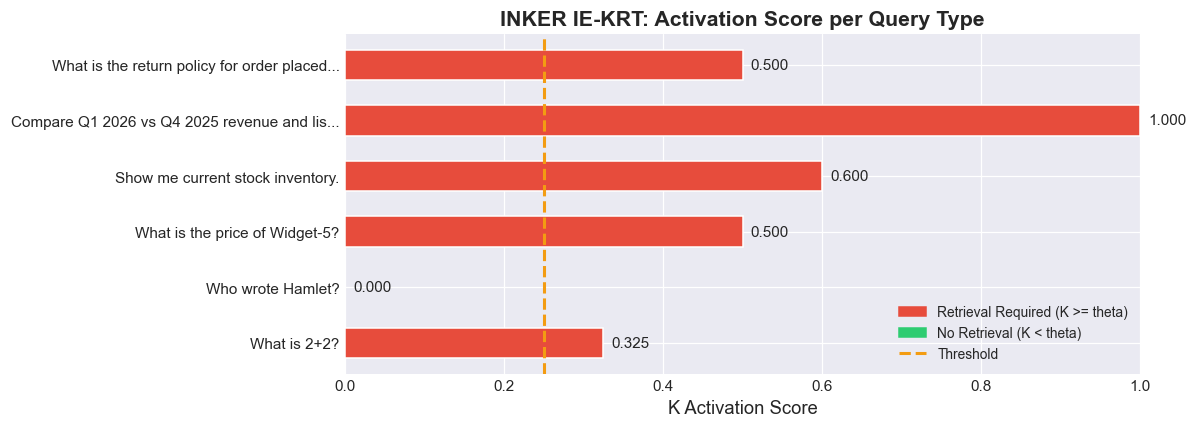

In [4]:
# Visualisation: K-activation score across query types
sample_queries = [
    "What is 2+2?",
    "Who wrote Hamlet?",
    "What is the price of Widget-5?",
    "Show me current stock inventory.",
    "Compare Q1 2026 vs Q4 2025 revenue and list products.",
    "What is the return policy for order placed today?",
]
k_scores = [round(krt.evaluate(q).k_activation_score, 4) for q in sample_queries]
colors   = ["#e74c3c" if s >= 0.25 else "#2ecc71" for s in k_scores]
labels   = [q[:42]+"..." if len(q)>42 else q for q in sample_queries]

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.barh(labels, k_scores, color=colors, edgecolor="white", height=0.55)
ax.axvline(0.25, color="#f39c12", lw=2, ls="--", label="Threshold theta=0.25")
for bar, val in zip(bars, k_scores):
    ax.text(val+0.01, bar.get_y()+bar.get_height()/2, f"{val:.3f}", va="center", fontsize=10)
ax.set_xlim(0, 1.0)
ax.set_xlabel("K Activation Score", fontsize=12)
ax.set_title("INKER IE-KRT: Activation Score per Query Type", fontsize=14, fontweight="bold")
red_p   = mpatches.Patch(color="#e74c3c", label="Retrieval Required (K >= theta)")
green_p = mpatches.Patch(color="#2ecc71", label="No Retrieval (K < theta)")
ax.legend(handles=[red_p, green_p,
    plt.Line2D([0],[0],color="#f39c12",lw=2,ls="--",label="Threshold")],
    loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

In [5]:
# =============================================================
# INKER IE-KQF  [B. INKER-Inspired Functionality]
# Source: inker/ie_kqf.py
# =============================================================

class IE_KQF:
    """Formulates expanded retrieval query q+ = concat(P, I).  [B]"""
    def formulate(self, query):
        entities    = QueryAnalyzer.extract_entities(query)
        stopwords   = {"what","is","the","a","an","of","for","to","in","on","with","how","which"}
        query_words = [w for w in query.split() if w.lower() not in stopwords]
        key_information = list(dict.fromkeys(entities + query_words))

        reasoning_phrases = []
        q_lower = query.lower()
        if "inventory" in q_lower or "stock" in q_lower or "quantity" in q_lower:
            reasoning_phrases.append("real-time inventory stock levels")
        if "return policy" in q_lower or "refund" in q_lower or "warranty" in q_lower:
            reasoning_phrases.append("official company policies document")
        if "sales" in q_lower or "revenue" in q_lower or "order" in q_lower:
            reasoning_phrases.append("order records database query")
        if "specification" in q_lower or "manual" in q_lower or "details" in q_lower:
            reasoning_phrases.append("technical product documentation")
        if not reasoning_phrases:
            reasoning_phrases.append("fact verification and detailed specs")

        # q+ = concat(P, I)
        p_str           = " ".join(reasoning_phrases)
        i_str           = " ".join(key_information[:8])
        retrieval_query = f"{i_str} {p_str}".strip()
        return {
            "original_query":    query,
            "key_information":   key_information,
            "reasoning_phrases": reasoning_phrases,
            "retrieval_query":   retrieval_query,
        }

kqf = IE_KQF()
for q in [
    "What is the current inventory stock of Widget-99?",
    "What is the return policy for order 5432?",
    "Compare Q1 2026 sales revenue versus Q4 2025.",
]:
    r = kqf.formulate(q)
    print(f"Original Query : {r['original_query']}")
    print(f"  Key Info (I) : {r['key_information'][:6]}")
    print(f"  Phrases  (P) : {r['reasoning_phrases']}")
    print(f"  Expanded q+  : {r['retrieval_query']}")
    print()

Original Query : What is the current inventory stock of Widget-99?
  Key Info (I) : ['What', 'Widget', 'Widget-99', 'current', 'inventory', 'stock']
  Phrases  (P) : ['real-time inventory stock levels']
  Expanded q+  : What Widget Widget-99 current inventory stock Widget-99? real-time inventory stock levels

Original Query : What is the return policy for order 5432?
  Key Info (I) : ['What', 'return', 'policy', 'order', '5432?']
  Phrases  (P) : ['official company policies document', 'order records database query']
  Expanded q+  : What return policy order 5432? official company policies document order records database query

Original Query : Compare Q1 2026 sales revenue versus Q4 2025.
  Key Info (I) : ['Q4', 'Q1', 'Compare', '2026', 'sales', 'revenue']
  Phrases  (P) : ['order records database query']
  Expanded q+  : Q4 Q1 Compare 2026 sales revenue versus 2025. order records database query



In [6]:
# =============================================================
# Synthetic 10,000-Source Catalogue & Pre-filtering  [C]
# Source: amora/prefilter.py
# =============================================================

random.seed(42)
np.random.seed(42)

SOURCE_TYPES = ["sql","api","vector","pdf","web"]
DOMAINS      = ["inventory","sales","hr","finance","support","general"]

def make_embedding(seed_text, dim=64):
    """Deterministic pseudo-embedding for demo purposes."""
    rng = np.random.default_rng(abs(hash(seed_text)) % (2**31))
    vec = rng.standard_normal(dim)
    return vec / (np.linalg.norm(vec) + 1e-9)

# Build synthetic catalogue of 10,000 sources
CATALOGUE = []
for i in range(10_000):
    stype  = random.choice(SOURCE_TYPES)
    domain = random.choice(DOMAINS)
    CATALOGUE.append({
        "source_id": f"SRC-{i:05d}",
        "name": f"{domain.capitalize()} {stype.upper()} Source #{i}",
        "type": stype, "domain": domain, "tool_type": stype,
        "active": random.random() > 0.1,       # 90% active
        "embedding": make_embedding(f"{domain} {stype} {i}"),
        "historical_success": round(random.uniform(0.5, 1.0), 3),
        "availability":       round(random.uniform(0.7, 1.0), 3),
        "freshness":          round(random.uniform(0.4, 1.0), 3),
        "cost":               round(random.uniform(0.0, 0.5), 3),
        "conflict_rate":      round(random.uniform(0.0, 0.3), 3),
        "updated_hours_ago":  random.randint(0, 720),
    })
print(f"Catalogue built: {len(CATALOGUE):,} sources | "
      f"Active: {sum(1 for s in CATALOGUE if s['active']):,}")

def cosine_similarity(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9))

def prefilter(retrieval_query, top_n=200, required_tool=None):
    """Two-stage pre-filtering.  [C]"""
    query_vec = make_embedding(retrieval_query)
    # Stage 2: Dense vector search (FAISS in production)
    scored = sorted(
        [(src, cosine_similarity(query_vec, src["embedding"])) for src in CATALOGUE],
        key=lambda x: x[1], reverse=True
    )[:top_n * 2]
    # Stage 1: Hard filters
    results = []
    for src, cos in scored:
        if not src["active"]: continue
        if required_tool and src["tool_type"] != required_tool: continue
        R_i = max(0.0, min(1.0, (cos + 1.0) / 2.0))   # Normalise to [0,1]
        results.append({**src, "R_i": round(R_i, 4)})
        if len(results) >= top_n: break
    return results

rq_demo    = "inventory stock levels Widget-99 real-time inventory stock levels"
candidates = prefilter(rq_demo, top_n=200)
print(f"\nPre-filtering: {len(CATALOGUE):,} -> {len(candidates)} candidates "
      f"({1 - len(candidates)/len(CATALOGUE):.1%} reduction)")
print("Top-5 by relevance R_i:")
for c in sorted(candidates, key=lambda x: x["R_i"], reverse=True)[:5]:
    print(f"  {c['source_id']}  domain={c['domain']:<10} type={c['type']:<8} R_i={c['R_i']:.4f}")

Catalogue built: 10,000 sources | Active: 8,967

Pre-filtering: 10,000 -> 200 candidates (98.0% reduction)
Top-5 by relevance R_i:
  SRC-01877  domain=sales      type=web      R_i=0.7247
  SRC-08241  domain=support    type=api      R_i=0.7071
  SRC-08806  domain=hr         type=sql      R_i=0.7013
  SRC-05912  domain=hr         type=pdf      R_i=0.6873
  SRC-02583  domain=hr         type=web      R_i=0.6849


In [7]:
# =============================================================
# AMORA Source Profiler  [C. AMORA Proposed Functionality]
# Source: amora/profiler.py
# =============================================================

ALPHA_RELIABILITY = 0.6    # Weight on success_rate
BETA_AVAILABILITY = 0.4    # Weight on availability  (alpha + beta = 1)
LAMBDA_FRESHNESS  = 0.005  # Decay constant per hour

def compute_reliability(src):
    """L_i = alpha*success_rate + beta*availability  (alpha+beta=1)"""
    sr  = src.get("historical_success", 1.0)
    av  = src.get("availability",       1.0)
    tot = ALPHA_RELIABILITY + BETA_AVAILABILITY
    return round(max(0.0, min(1.0, (ALPHA_RELIABILITY/tot)*sr + (BETA_AVAILABILITY/tot)*av)), 4)

def compute_freshness(src):
    """F_i = exp(-lambda * delta_t_hours)"""
    return round(max(0.0, min(1.0,
        math.exp(-LAMBDA_FRESHNESS * src.get("updated_hours_ago", 0)))), 4)

def compute_historical_success(src):
    return round(max(0.0, min(1.0, src.get("historical_success", 1.0))), 4)

def compute_cost(src):
    return round(max(0.0, min(1.0, src.get("cost", 0.0))), 4)

def compute_conflict_rate(src):
    return round(max(0.0, min(1.0, src.get("conflict_rate", 0.0))), 4)

def profile_source(src):
    return {
        "source_id": src["source_id"], "name": src["name"],
        "type": src["type"], "domain": src["domain"], "tool_type": src["tool_type"],
        "R_i": src.get("R_i", 0.5),
        "L_i": compute_reliability(src),
        "F_i": compute_freshness(src),
        "H_i": compute_historical_success(src),
        "C_i": compute_cost(src),
        "K_i": compute_conflict_rate(src),
    }

top10    = sorted(candidates, key=lambda x: x["R_i"], reverse=True)[:10]
profiles = [profile_source(c) for c in top10]
print(f"{'ID':<12} {'Type':<8} {'Domain':<12} R_i   L_i   F_i   H_i   C_i   K_i")
print("-" * 72)
for p in profiles:
    print(f"{p['source_id']:<12} {p['type']:<8} {p['domain']:<12} "
          f"{p['R_i']:5.3f} {p['L_i']:5.3f} {p['F_i']:5.3f} "
          f"{p['H_i']:5.3f} {p['C_i']:5.3f} {p['K_i']:5.3f}")

ID           Type     Domain       R_i   L_i   F_i   H_i   C_i   K_i
------------------------------------------------------------------------
SRC-01877    web      sales        0.725 0.727 0.048 0.671 0.467 0.118
SRC-08241    api      support      0.707 0.917 0.543 0.977 0.125 0.167
SRC-08806    sql      hr           0.701 0.680 0.413 0.612 0.234 0.280
SRC-05912    pdf      hr           0.687 0.869 0.291 0.968 0.136 0.005
SRC-02583    web      hr           0.685 0.791 0.900 0.772 0.314 0.208
SRC-07511    pdf      support      0.684 0.885 0.068 0.900 0.393 0.200
SRC-01782    web      inventory    0.684 0.786 0.499 0.776 0.130 0.100
SRC-06926    sql      support      0.683 0.685 0.149 0.641 0.130 0.012
SRC-02053    web      inventory    0.683 0.671 0.245 0.525 0.352 0.103
SRC-03625    pdf      support      0.682 0.802 0.043 0.682 0.496 0.238


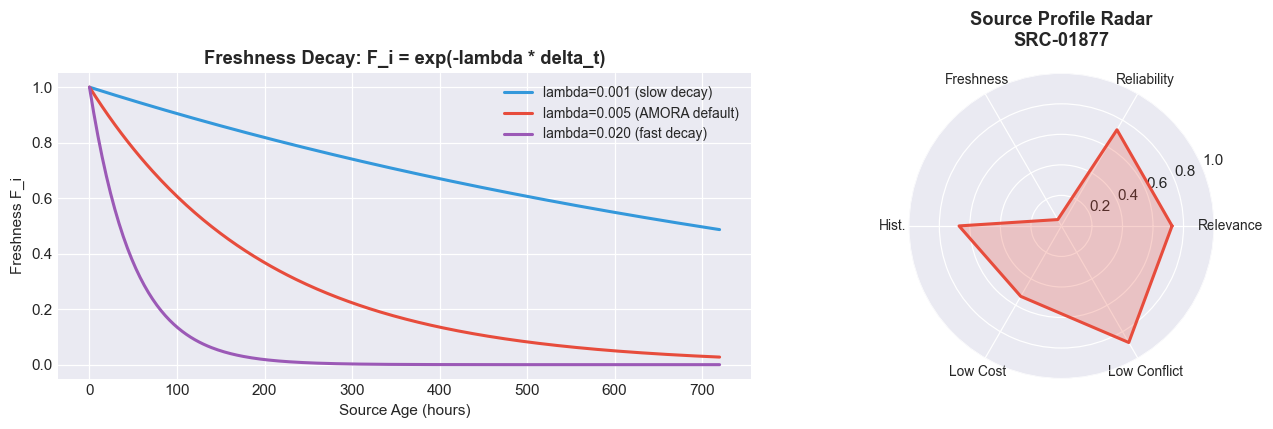

In [8]:
# Visualisation: Freshness decay curves + Source profile radar chart
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Left: Freshness decay for three lambda values
t_range = np.linspace(0, 720, 300)
for lam, label, col in [
    (0.001, "lambda=0.001 (slow decay)",   "#3498db"),
    (0.005, "lambda=0.005 (AMORA default)","#e74c3c"),
    (0.020, "lambda=0.020 (fast decay)",   "#9b59b6"),
]:
    axes[0].plot(t_range, np.exp(-lam * t_range), label=label, lw=2, color=col)
axes[0].set_xlabel("Source Age (hours)")
axes[0].set_ylabel("Freshness F_i")
axes[0].set_title("Freshness Decay: F_i = exp(-lambda * delta_t)", fontweight="bold")
axes[0].legend(fontsize=9)

# Right: Radar chart for top source
p0      = profiles[0]
metrics = ["Relevance", "Reliability", "Freshness", "Hist.", "Low Cost", "Low Conflict"]
values  = [p0["R_i"], p0["L_i"], p0["F_i"], p0["H_i"], 1-p0["C_i"], 1-p0["K_i"]]
angles  = np.linspace(0, 2*np.pi, len(metrics), endpoint=False).tolist()
values += values[:1]; angles += angles[:1]
ax_r    = axes[1]; ax_r.remove()
ax_r    = fig.add_subplot(1, 2, 2, projection="polar")
ax_r.plot(angles, values, color="#e74c3c", lw=2)
ax_r.fill(angles, values, color="#e74c3c", alpha=0.25)
ax_r.set_thetagrids(np.degrees(angles[:-1]), metrics, fontsize=9)
ax_r.set_ylim(0, 1)
ax_r.set_title(f"Source Profile Radar\n{p0['source_id']}", fontweight="bold", pad=18)
plt.tight_layout(); plt.show()

In [9]:
# =============================================================
# AMORA Dynamic Weight Generator  [C. AMORA Proposed Functionality]
# Source: amora/weights.py
# =============================================================

class DynamicWeights:
    def __init__(self, W_r, W_l, W_f, W_c, W_h, W_k):
        self.W_r = W_r   # Relevance
        self.W_l = W_l   # Reliability
        self.W_f = W_f   # Freshness
        self.W_c = W_c   # Cost penalty
        self.W_h = W_h   # Historical success
        self.W_k = W_k   # Conflict penalty
    def to_dict(self):
        return {
            "Relevance (W_r)":        round(self.W_r,4),
            "Reliability (W_l)":      round(self.W_l,4),
            "Freshness (W_f)":        round(self.W_f,4),
            "Cost penalty (W_c)":     round(self.W_c,4),
            "Hist. Success (W_h)":    round(self.W_h,4),
            "Conflict penalty (W_k)": round(self.W_k,4),
        }
    def verify_sum(self):
        return round(self.W_r+self.W_l+self.W_f+self.W_c+self.W_h+self.W_k, 6)

class DynamicWeightGenerator:
    """Query-aware weight generator with strict normalisation guarantee.  [C]"""
    @classmethod
    def generate_weights(cls, query, cost_sensitive=False, conflict_sensitive=False):
        # Step 1: Extract query features
        q_complexity       = QueryAnalyzer.estimate_complexity(query)
        q_freshness_need   = QueryAnalyzer.detect_temporal_need(query)
        q_reliability_need = QueryAnalyzer.detect_factual_need(query)
        q_ambiguity        = max(0.0, 1.0 - q_complexity)
        # Step 2: Baseline weights
        w_r, w_l, w_f, w_c, w_h, w_k = 0.30, 0.20, 0.15, 0.10, 0.15, 0.10
        # Rule 1: High temporal urgency -> boost Freshness
        if q_freshness_need > 0.5:
            d = 0.25*q_freshness_need; w_f += d; w_r -= d*0.5; w_h -= d*0.5
        # Rule 2: Factual lookup -> boost Reliability
        if q_reliability_need > 0.5:
            d = 0.20*q_reliability_need; w_l += d; w_c -= d*0.5; w_k -= d*0.5
        # Rule 3: Cost-sensitive
        if cost_sensitive:
            w_c += 0.20; w_r -= 0.10; w_f -= 0.10
        # Rule 4: Ambiguous query -> boost Relevance
        if q_ambiguity > 0.6:
            w_r += 0.15; w_h -= 0.15
        # Rule 5: Conflict sensitivity
        if conflict_sensitive or "compare" in query.lower() or "versus" in query.lower():
            w_k += 0.15; w_l += 0.05; w_r -= 0.10
        # Step 3: Clamp minimums
        w_r=max(0.05,w_r); w_l=max(0.05,w_l); w_f=max(0.05,w_f)
        w_c=max(0.02,w_c); w_h=max(0.05,w_h); w_k=max(0.02,w_k)
        # Step 4: Normalise -> sum = 1.0 exactly
        total = w_r+w_l+w_f+w_c+w_h+w_k
        return DynamicWeights(w_r/total, w_l/total, w_f/total,
                              w_c/total, w_h/total, w_k/total)

weight_demos = [
    ("What is the current real-time inventory status?",  False, False),
    ("What is the official return policy?",              False, False),
    ("Compare sales Q1 2026 versus Q4 2025.",            False, True),
    ("Show sales data.",                                 True,  False),
]
print(f"{'Query':<45}  W_r    W_l    W_f    W_c    W_h    W_k    Sum")
print("-" * 100)
weight_results = []
for q, cs, cf in weight_demos:
    w = DynamicWeightGenerator.generate_weights(q, cost_sensitive=cs, conflict_sensitive=cf)
    weight_results.append((q, w))
    print(f"{q[:43]:<45}  {w.W_r:6.4f} {w.W_l:6.4f} {w.W_f:6.4f} "
          f"{w.W_c:6.4f} {w.W_h:6.4f} {w.W_k:6.4f}  {w.verify_sum():.4f}")

Query                                          W_r    W_l    W_f    W_c    W_h    W_k    Sum
----------------------------------------------------------------------------------------------------
What is the current real-time inventory sta    0.1707 0.3317 0.3902 0.0293 0.0488 0.0293  1.0000
What is the official return policy?            0.4286 0.3238 0.1429 0.0286 0.0476 0.0286  1.0000
Compare sales Q1 2026 versus Q4 2025.          0.0909 0.3545 0.3182 0.0273 0.0455 0.1636  1.0000
Show sales data.                               0.3333 0.1905 0.0476 0.2857 0.0476 0.0952  1.0000


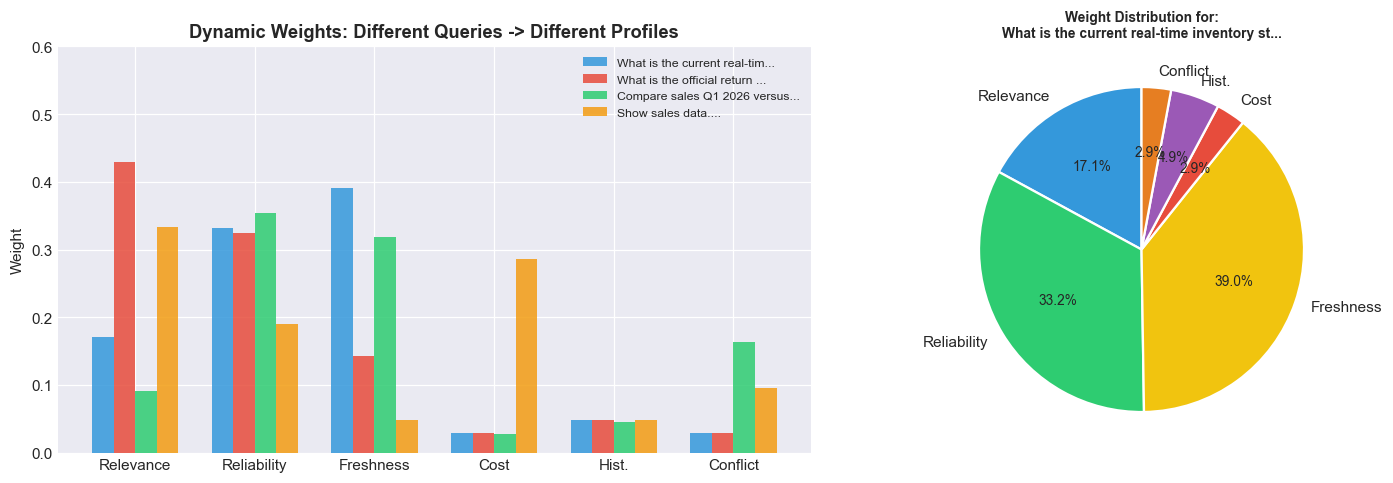

In [10]:
# Visualisation: Weight profiles as grouped bars + pie
weight_names = ["Relevance","Reliability","Freshness","Cost","Hist.","Conflict"]
data         = np.array([[w.W_r,w.W_l,w.W_f,w.W_c,w.W_h,w.W_k] for _,w in weight_results])
x, bw        = np.arange(len(weight_names)), 0.18
q_colors     = ["#3498db","#e74c3c","#2ecc71","#f39c12"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for i,(row,col) in enumerate(zip(data, q_colors)):
    lbl = weight_demos[i][0][:28]+"..."
    axes[0].bar(x + (i-1.5)*bw, row, bw, label=lbl, color=col, alpha=0.85)
axes[0].set_xticks(x); axes[0].set_xticklabels(weight_names, fontsize=10)
axes[0].set_ylabel("Weight"); axes[0].set_ylim(0, 0.6)
axes[0].set_title("Dynamic Weights: Different Queries -> Different Profiles", fontweight="bold")
axes[0].legend(fontsize=8, loc="upper right")

q0, w0 = weight_results[0]
vals = [w0.W_r,w0.W_l,w0.W_f,w0.W_c,w0.W_h,w0.W_k]
lbls = ["Relevance","Reliability","Freshness","Cost","Hist.","Conflict"]
cols = ["#3498db","#2ecc71","#f1c40f","#e74c3c","#9b59b6","#e67e22"]
wedges,texts,autotexts = axes[1].pie(vals, labels=lbls, colors=cols,
    autopct="%1.1f%%", startangle=90,
    wedgeprops={"edgecolor":"white","linewidth":1.5})
for at in autotexts: at.set_fontsize(9)
axes[1].set_title(f"Weight Distribution for:\n{q0[:42]}...", fontsize=9, fontweight="bold")
plt.tight_layout(); plt.show()

In [11]:
# =============================================================
# AMORA Multi-Objective Ranker  [C. AMORA Proposed Functionality]
# Source: amora/ranking.py
# =============================================================

def compute_amora_score(p, w):
    """Score_i = W_r*R_i + W_l*L_i + W_f*F_i + W_h*H_i - W_c*C_i - W_k*K_i"""
    return round(w.W_r*p["R_i"] + w.W_l*p["L_i"] + w.W_f*p["F_i"]
                 + w.W_h*p["H_i"] - w.W_c*p["C_i"] - w.W_k*p["K_i"], 4)

def compute_pareto_ranks(sources):
    """Fast Non-Dominated Sorting algorithm.  [C]"""
    n = len(sources)
    if n == 0: return sources
    dom_counts = [0]*n; dom_sets = [[] for _ in range(n)]; ranks = [0]*n
    def obj(s): return (s["R_i"],s["L_i"],s["F_i"],s["H_i"],-s["C_i"],-s["K_i"])
    for i in range(n):
        for j in range(n):
            if i == j: continue
            iv, jv = obj(sources[i]), obj(sources[j])
            if all(a>=b for a,b in zip(iv,jv)) and any(a>b for a,b in zip(iv,jv)):
                dom_sets[i].append(j)
            elif all(b>=a for a,b in zip(iv,jv)) and any(b>a for a,b in zip(iv,jv)):
                dom_counts[i] += 1
    front = [i for i in range(n) if dom_counts[i]==0]
    for i in front: ranks[i] = 1
    current, fronts = 1, [front]
    while fronts[current-1]:
        nf = []
        for i in fronts[current-1]:
            for j in dom_sets[i]:
                dom_counts[j] -= 1
                if dom_counts[j] == 0:
                    ranks[j] = current + 1; nf.append(j)
        current += 1; fronts.append(nf)
    for i in range(n): sources[i]["pareto_rank"] = ranks[i]
    return sources

def rank_sources(candidates, weights, top_k=5, mode="weighted"):
    """Full ranking pipeline.  [C]"""
    profiled = [profile_source(c) for c in candidates]
    for p in profiled: p["score"] = compute_amora_score(p, weights)
    if mode == "pareto":
        profiled = compute_pareto_ranks(profiled)
        profiled.sort(key=lambda s: (s["pareto_rank"], -s["score"]))
    else:
        profiled.sort(key=lambda s: s["score"], reverse=True)
    return profiled[:top_k]

# Demo
DEMO_QUERY = "What is the current inventory stock of Widget-99?"
W          = DynamicWeightGenerator.generate_weights(DEMO_QUERY)

print("Dynamic Weights generated for demo query:")
for k, v in W.to_dict().items():
    bar = chr(0x2588) * int(v*30)
    print(f"  {k:<28} {v:.4f}  {bar}")
print(f"  {'Sum':<28} {W.verify_sum():.4f}  (must = 1.000)")

ranked_w = rank_sources(candidates, W, top_k=5, mode="weighted")
ranked_p = rank_sources(candidates, W, top_k=5, mode="pareto")

print("\n--- Weighted Mode Top-5 ---")
print(f"{'#':<4} {'ID':<12} {'Type':<8} {'Score':>7} {'R_i':>5} {'L_i':>5} {'F_i':>5} {'H_i':>5} {'C_i':>5} {'K_i':>5}")
print("-"*70)
for i, s in enumerate(ranked_w, 1):
    print(f"{i:<4} {s['source_id']:<12} {s['type']:<8} {s['score']:>7.4f} "
          f"{s['R_i']:>5.3f} {s['L_i']:>5.3f} {s['F_i']:>5.3f} "
          f"{s['H_i']:>5.3f} {s['C_i']:>5.3f} {s['K_i']:>5.3f}")

print("\n--- Pareto Mode Top-5 ---")
for i, s in enumerate(ranked_p, 1):
    print(f"{i:<4} Pareto Rank={s.get('pareto_rank','?'):<3} "
          f"{s['source_id']:<12} Score={s['score']:>7.4f}")

Dynamic Weights generated for demo query:
  Relevance (W_r)              0.1923  █████
  Reliability (W_l)            0.3846  ███████████
  Freshness (W_f)              0.3365  ██████████
  Cost penalty (W_c)           0.0192  
  Hist. Success (W_h)          0.0481  █
  Conflict penalty (W_k)       0.0192  
  Sum                          1.0000  (must = 1.000)

--- Weighted Mode Top-5 ---
#    ID           Type       Score   R_i   L_i   F_i   H_i   C_i   K_i
----------------------------------------------------------------------
1    SRC-01495    sql       0.8225 0.635 0.851 0.995 0.940 0.341 0.029
2    SRC-08265    vector    0.8140 0.638 0.857 0.975 0.832 0.162 0.172
3    SRC-01282    pdf       0.8112 0.629 0.945 0.865 0.941 0.301 0.206
4    SRC-09792    sql       0.7781 0.628 0.787 0.970 0.739 0.182 0.197
5    SRC-00817    web       0.7780 0.627 0.904 0.815 0.878 0.217 0.128

--- Pareto Mode Top-5 ---
1    Pareto Rank=1   SRC-01495    Score= 0.8225
2    Pareto Rank=1   SRC-08265    Sc

In [ ]:
# Visualisation: Ranking comparison + Pareto frontier scatter
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

type_color = {"sql":"#3498db","api":"#e74c3c","vector":"#2ecc71","pdf":"#f39c12","web":"#9b59b6"}
top10 = rank_sources(candidates, W, top_k=10, mode="weighted")

# Left: AMORA score bars
ids  = [s["source_id"] for s in top10]
scrs = [s["score"] for s in top10]
axes[0].barh(ids[::-1], scrs[::-1],
             color=[type_color.get(s["type"],"grey") for s in top10[::-1]],
             edgecolor="white", height=0.6)
for i, (_, sc) in enumerate(zip(ids[::-1], scrs[::-1])):
    axes[0].text(sc+0.003, i, f"{sc:.4f}", va="center", fontsize=8)
axes[0].set_xlabel("AMORA Score")
axes[0].set_title("Top-10 Sources — Weighted Mode", fontweight="bold")
axes[0].legend(handles=[mpatches.Patch(color=c,label=t.upper()) for t,c in type_color.items()],
               fontsize=8)

# Right: Pareto frontier scatter (Freshness vs Relevance)
all_p = [profile_source(c) for c in candidates[:150]]
for p in all_p: p["score"] = compute_amora_score(p, W)
all_p = compute_pareto_ranks(all_p)
rank_colors = {1:"#e74c3c", 2:"#f39c12", 3:"#3498db"}
for p in all_p:
    rk = min(p.get("pareto_rank",3), 3)
    axes[1].scatter(p["R_i"], p["F_i"], color=rank_colors[rk],
                    s=55, alpha=0.75, edgecolors="white", lw=0.4)
for rk, col in rank_colors.items():
    axes[1].scatter([], [], color=col, label=f"Pareto Rank {rk}", s=60)
axes[1].set_xlabel("Relevance R_i"); axes[1].set_ylabel("Freshness F_i")
axes[1].set_title("Pareto Frontier: Relevance vs Freshness", fontweight="bold")
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

In [12]:
# =============================================================
# AMORA Evidence Conflict Detector  [C. AMORA Proposed Functionality]
# Source: amora/conflict.py
# =============================================================

class ConflictDetector:
    """Detects numeric/date conflicts across evidence snippets.  [C]"""
    @classmethod
    def analyze_evidence_conflict(cls, evidence_items):
        if len(evidence_items) <= 1:
            return {"conflict_score": 0.0, "flagged_conflicts": []}
        numbers_by_source, dates_by_source = {}, {}
        for item in evidence_items:
            s = item.get("source_name", item.get("source_id", "Unknown"))
            t = str(item.get("content", ""))
            numbers_by_source[s] = set(re.findall(r'\b\d+(?:\.\d+)?\b', t))
            dates_by_source[s]   = set(re.findall(r'\b(?:19|20)\d{2}\b', t))
        conflicts = []
        for i in range(len(evidence_items)):
            for j in range(i+1, len(evidence_items)):
                s1 = evidence_items[i].get("source_name", "S1")
                s2 = evidence_items[j].get("source_name", "S2")
                n1, n2 = numbers_by_source.get(s1,set()), numbers_by_source.get(s2,set())
                if n1 and n2 and n1.isdisjoint(n2):
                    conflicts.append({"type":"numeric_disagreement","sources":[s1,s2],
                        "details":f"Numeric mismatch: {s1}={list(n1)[:3]}, {s2}={list(n2)[:3]}"})
                d1, d2 = dates_by_source.get(s1,set()), dates_by_source.get(s2,set())
                if d1 and d2 and d1.isdisjoint(d2):
                    conflicts.append({"type":"date_disagreement","sources":[s1,s2],
                        "details":f"Date mismatch: {s1}={list(d1)}, {s2}={list(d2)}"})
        return {"conflict_score": round(min(1.0, len(conflicts)*0.3), 4),
                "flagged_conflicts": conflicts}

# Demo
ev_ok = [
    {"source_name":"SQL_DB", "content":"Widget-99 stock: 150 units, 2026."},
    {"source_name":"API",    "content":"Widget-99 available: 150 items, 2026."},
]
ev_bad = [
    {"source_name":"SQL_DB", "content":"Widget-99 stock: 150 units, 2026."},
    {"source_name":"Web",    "content":"Widget-99: 90 units as of 2025."},
    {"source_name":"PDF",    "content":"Stock for Widget-99 is 205 units (2024 catalogue)."},
]
r1 = ConflictDetector.analyze_evidence_conflict(ev_ok)
r2 = ConflictDetector.analyze_evidence_conflict(ev_bad)
print("Scenario A — Consistent Evidence:")
print(f"  Conflict Score : {r1['conflict_score']}  (no conflicts detected)")
print("\nScenario B — Conflicting Evidence:")
print(f"  Conflict Score : {r2['conflict_score']}  WARNING")
for c in r2["flagged_conflicts"]:
    print(f"  [{c['type']}] {c['details']}")

Scenario A — Consistent Evidence:
  Conflict Score : 0.0  (no conflicts detected)

Scenario B — Conflicting Evidence:
  Conflict Score : 0.9  WARNING
  [date_disagreement] Date mismatch: SQL_DB=['2026'], Web=['2025']
  [date_disagreement] Date mismatch: SQL_DB=['2026'], PDF=['2024']
  [date_disagreement] Date mismatch: Web=['2025'], PDF=['2024']


In [13]:
# =============================================================
# Evidence Fusion Engine  [C. AMORA Proposed Functionality]
# Source: retrieval/fusion.py
# =============================================================

class EvidenceFusionEngine:
    """Deduplicates, scores, conflict-checks, and formats evidence.  [C]"""
    @classmethod
    def fuse_evidence(cls, raw_results):
        seen, deduped = set(), []
        for item in raw_results:
            content = str(item.get("content","")).strip()
            if not content: continue
            key = content.lower()[:120]
            if key in seen: continue
            seen.add(key)
            ret = float(item.get("retrieval_score", 0.8))
            src = float(item.get("source_score",    0.8))
            deduped.append({
                "source_id":       item.get("source_id","unknown"),
                "source_name":     item.get("source_name","Unknown"),
                "tool":            item.get("tool_type","tool"),
                "content":         content,
                "timestamp":       item.get("timestamp",""),
                "retrieval_score": round(ret, 4),
                "source_score":    round(src, 4),
                "fused_score":     round(ret*0.4 + src*0.6, 4),
            })
        deduped.sort(key=lambda e: e["fused_score"], reverse=True)
        conflict_report = ConflictDetector.analyze_evidence_conflict(deduped)
        blocks = []
        for idx, e in enumerate(deduped, 1):
            blocks.append(
                f"[EVIDENCE {idx}]\nSource: {e['source_name']} | Tool: {e['tool']}\n"
                f"Quality: {e['source_score']:.4f} | Retrieval: {e['retrieval_score']:.4f}\n"
                f"Timestamp: {e['timestamp']}\nContent: {e['content']}"
            )
        return {
            "evidence_items": deduped,
            "conflict_detected": len(conflict_report["flagged_conflicts"]) > 0,
            "conflict_score":  conflict_report["conflict_score"],
            "flagged_conflicts": conflict_report["flagged_conflicts"],
            "formatted_prompt_context": "\n" + "="*40 + "\n" + ("\n" + "-"*40 + "\n").join(blocks),
        }

raw_evidence = [
    {"source_id":"SRC-001","source_name":"SQL_Inventory_DB","tool_type":"sql",
     "retrieval_score":0.91,"source_score":0.87,"timestamp":"2026-09-07T00:00:00Z",
     "content":"Widget-99 stock: 150 units, updated 2026."},
    {"source_id":"SRC-042","source_name":"ERP_REST_API","tool_type":"api",
     "retrieval_score":0.84,"source_score":0.92,"timestamp":"2026-09-07T00:01:00Z",
     "content":"GET /inventory/Widget-99 -> {available:148, reserved:2}"},
    {"source_id":"SRC-001","source_name":"SQL_Inventory_DB","tool_type":"sql",
     "retrieval_score":0.91,"source_score":0.87,"timestamp":"2026-09-07T00:00:00Z",
     "content":"Widget-99 stock: 150 units, updated 2026."},   # Duplicate
    {"source_id":"SRC-777","source_name":"PDF_Manual","tool_type":"pdf",
     "retrieval_score":0.62,"source_score":0.70,"timestamp":"2026-01-01T00:00:00Z",
     "content":"Widget-99 max capacity 500 units. See product manual page 42."},
]
fusion = EvidenceFusionEngine.fuse_evidence(raw_evidence)
print(f"Input: {len(raw_evidence)} items  |  "
      f"After dedup: {len(fusion['evidence_items'])} items  |  "
      f"Conflict: {fusion['conflict_detected']} (score={fusion['conflict_score']})")
print("\nEvidence ranked by fused score:")
for e in fusion["evidence_items"]:
    print(f"  {e['source_name']:<22}  ret={e['retrieval_score']:.4f}  "
          f"src={e['source_score']:.4f}  fused={e['fused_score']:.4f}")
print("\nFormatted Prompt Context (excerpt):")
print(fusion["formatted_prompt_context"][:500])

Input: 4 items  |  After dedup: 3 items  |  Conflict: False (score=0.0)

Evidence ranked by fused score:
  ERP_REST_API            ret=0.8400  src=0.9200  fused=0.8880
  SQL_Inventory_DB        ret=0.9100  src=0.8700  fused=0.8860
  PDF_Manual              ret=0.6200  src=0.7000  fused=0.6680

Formatted Prompt Context (excerpt):

[EVIDENCE 1]
Source: ERP_REST_API | Tool: api
Quality: 0.9200 | Retrieval: 0.8400
Timestamp: 2026-09-07T00:01:00Z
Content: GET /inventory/Widget-99 -> {available:148, reserved:2}
----------------------------------------
[EVIDENCE 2]
Source: SQL_Inventory_DB | Tool: sql
Quality: 0.8700 | Retrieval: 0.9100
Timestamp: 2026-09-07T00:00:00Z
Content: Widget-99 stock: 150 units, updated 2026.
----------------------------------------
[EVIDENCE 3]
Source: PDF_Man


In [14]:
# =============================================================
# FULL END-TO-END AMORA PIPELINE DEMO
# =============================================================

USER_QUERY = "What is the current stock inventory of Widget-99 and its latest price?"

print("=" * 70)
print(f"  USER QUERY: {USER_QUERY}")
print("=" * 70)

# STEP 1: IE-KRT — WHEN to retrieve?
print("\n[STEP 1] INKER IE-KRT: Knowledge Retrieval Trigger")
krt   = IE_KRT(activation_threshold=0.25)
krt_r = krt.evaluate(USER_QUERY)
print(krt_r)

# STEP 2: IE-KQF — WHAT to retrieve?
print("\n[STEP 2] INKER IE-KQF: Query Formulation")
kqf_r = IE_KQF().formulate(USER_QUERY)
print(f"  Expanded q+ : {kqf_r['retrieval_query']}")

# STEP 3: Pre-filtering
print("\n[STEP 3] AMORA Pre-filtering (10,000 -> 200 candidates)")
cands = prefilter(kqf_r["retrieval_query"], top_n=200)
print(f"  Catalogue size   : {len(CATALOGUE):,}")
print(f"  After pre-filter : {len(cands)} candidates")
print(f"  Reduction ratio  : {1 - len(cands)/len(CATALOGUE):.1%}")

# STEP 4: Dynamic Weight Generation
print("\n[STEP 4] AMORA Dynamic Weight Generation")
W = DynamicWeightGenerator.generate_weights(USER_QUERY)
for name, val in W.to_dict().items():
    bar = chr(0x2588) * int(val * 25)
    print(f"  {name:<28} {val:.4f}  {bar}")
print(f"  {'Sum':<28} {W.verify_sum():.4f}  (must = 1.000)")

# STEP 5: Ranking
print("\n[STEP 5] AMORA Multi-Objective Ranking (Top-5)")
ranked = rank_sources(cands, W, top_k=5, mode="weighted")
for i, s in enumerate(ranked, 1):
    print(f"  {i}. {s['source_id']:<12} type={s['type']:<8} "
          f"score={s['score']:.4f} domain={s['domain']}")

# STEP 6: Simulated Tool Retrieval
print("\n[STEP 6] Simulated Tool Retrieval from Top Sources")
sim_ev = [
    {"source_id":ranked[0]["source_id"],"source_name":ranked[0]["name"],
     "tool_type":ranked[0]["type"],"retrieval_score":ranked[0]["R_i"],
     "source_score":ranked[0]["score"],"timestamp":"2026-09-07T00:05:00Z",
     "content":"Widget-99 current stock: 150 units. Last updated 2026-09-07."},
    {"source_id":ranked[1]["source_id"],"source_name":ranked[1]["name"],
     "tool_type":ranked[1]["type"],"retrieval_score":ranked[1]["R_i"],
     "source_score":ranked[1]["score"],"timestamp":"2026-09-07T00:05:01Z",
     "content":"Widget-99 latest price: $24.99 USD. Effective Q3 2026."},
]
print(f"  Retrieved {len(sim_ev)} evidence items from top-2 sources.")

# STEP 7: Evidence Fusion
print("\n[STEP 7] Evidence Fusion & Conflict Detection")
fusion = EvidenceFusionEngine.fuse_evidence(sim_ev)
print(f"  Items after dedup    : {len(fusion['evidence_items'])}")
print(f"  Conflict detected    : {fusion['conflict_detected']} "
      f"(score={fusion['conflict_score']})")

# STEP 8: LLM Answer (Mock)
print("\n[STEP 8] Qwen LLM Final Answer Generation (Mock)")
conflict_note = " [CONFLICT ALERT INCLUDED]" if fusion["conflict_detected"] else ""
answer = (
    f"GROUNDED ANSWER{conflict_note}:\n"
    f"Based on {len(fusion['evidence_items'])} retrieved evidence items from "
    f"authoritative enterprise sources:\n\n"
    f"  - Widget-99 current stock: 150 units (as of 2026-09-07)\n"
    f"  - Widget-99 latest price : $24.99 USD (effective Q3 2026)"
)
print("\n" + "-"*55)
print(answer)
print("-"*55)
print("\nEnd-to-End AMORA Pipeline Complete.")

  USER QUERY: What is the current stock inventory of Widget-99 and its latest price?

[STEP 1] INKER IE-KRT: Knowledge Retrieval Trigger
  Decision   : YES — RETRIEVE
  K score    : 1.0000
  Confidence : 0.9000
  Mode       : Mode B (Query-Uncertainty Fallback)
  Reason     : High external knowledge need (K=1.000 >= theta=0.250).

[STEP 2] INKER IE-KQF: Query Formulation
  Expanded q+ : What Widget Widget-99 current stock inventory and its real-time inventory stock levels

[STEP 3] AMORA Pre-filtering (10,000 -> 200 candidates)
  Catalogue size   : 10,000
  After pre-filter : 200 candidates
  Reduction ratio  : 98.0%

[STEP 4] AMORA Dynamic Weight Generation
  Relevance (W_r)              0.1643  ████
  Reliability (W_l)            0.3756  █████████
  Freshness (W_f)              0.3756  █████████
  Cost penalty (W_c)           0.0188  
  Hist. Success (W_h)          0.0469  █
  Conflict penalty (W_k)       0.0188  
  Sum                          1.0000  (must = 1.000)

[STEP 5] AMORA 

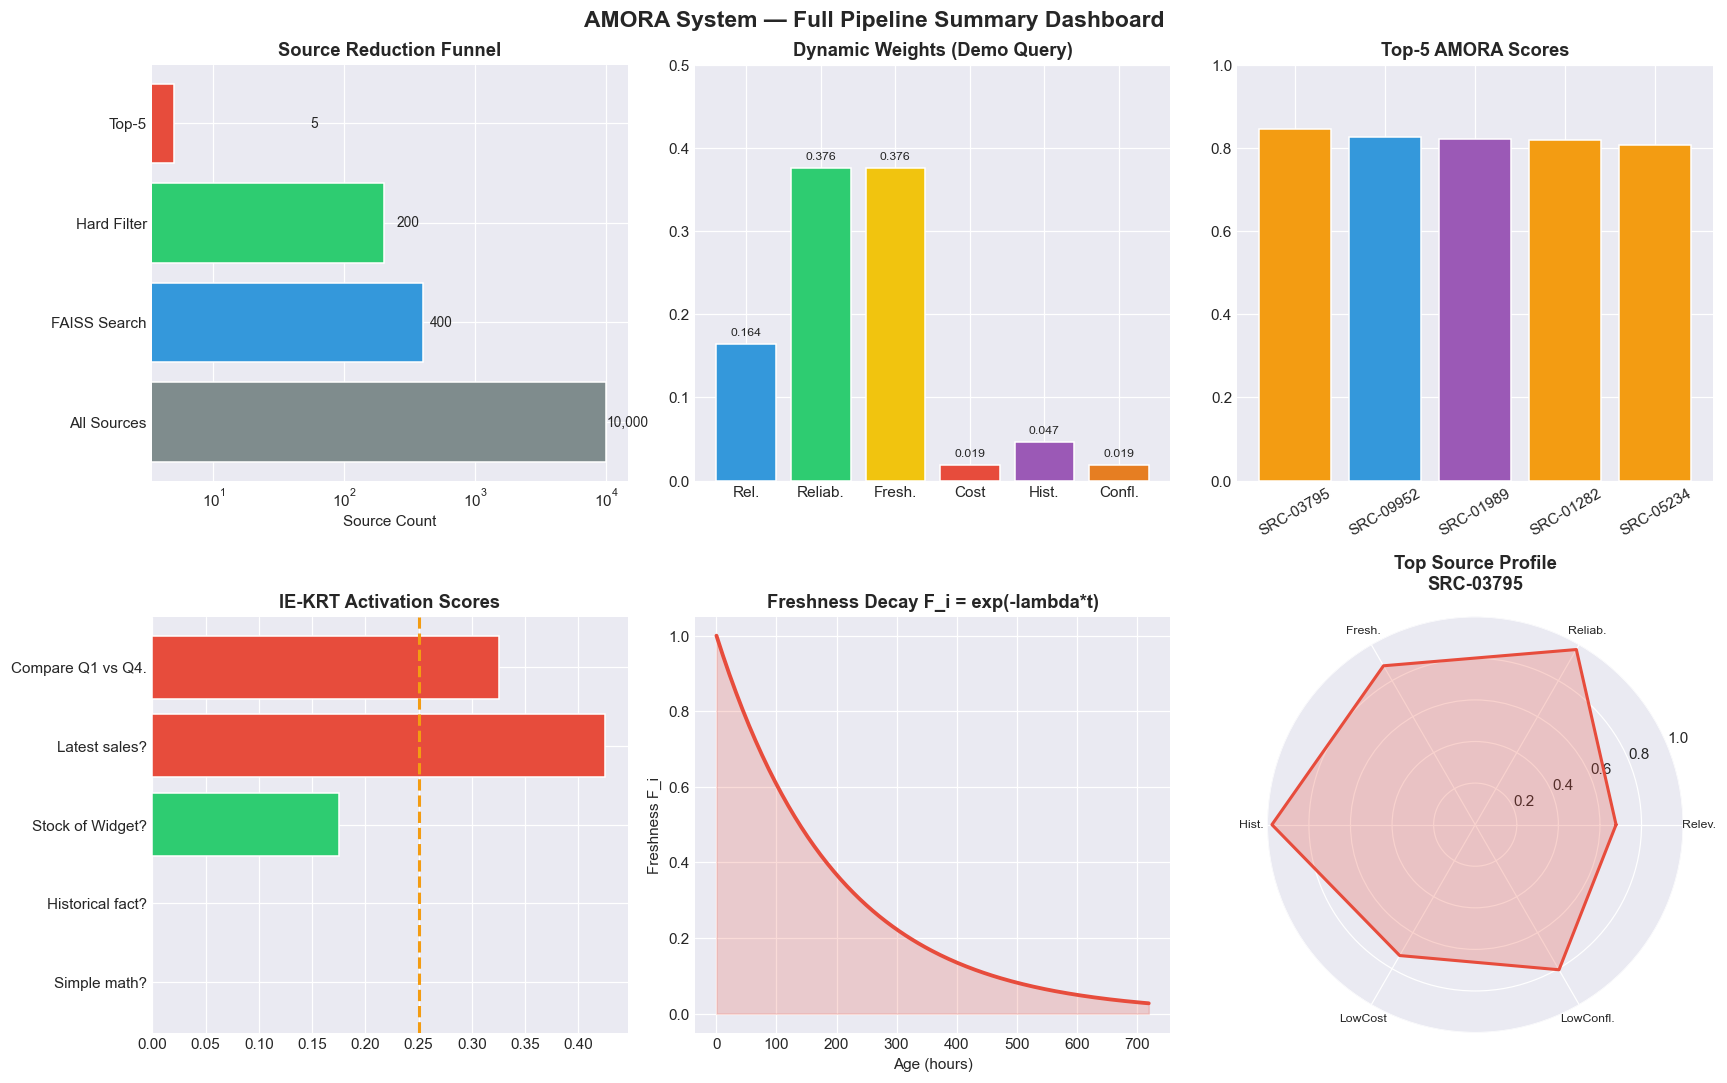

In [15]:
# Full pipeline summary dashboard
fig = plt.figure(figsize=(16, 10))
fig.suptitle("AMORA System — Full Pipeline Summary Dashboard",
             fontsize=15, fontweight="bold")

type_color = {"sql":"#3498db","api":"#e74c3c","vector":"#2ecc71","pdf":"#f39c12","web":"#9b59b6"}

# Panel 1: Source Reduction Funnel
ax1 = fig.add_subplot(2, 3, 1)
stages     = ["All Sources","FAISS Search","Hard Filter","Top-5"]
stage_vals = [10000, 400, len(cands), 5]
ax1.barh(stages, stage_vals, color=["#7f8c8d","#3498db","#2ecc71","#e74c3c"], edgecolor="white")
for y, v in enumerate(stage_vals):
    ax1.text(v+50, y, f"{v:,}", va="center", fontsize=9)
ax1.set_xlabel("Source Count"); ax1.set_title("Source Reduction Funnel", fontweight="bold")
ax1.set_xscale("log")

# Panel 2: Dynamic Weights
ax2 = fig.add_subplot(2, 3, 2)
w_n = ["Rel.","Reliab.","Fresh.","Cost","Hist.","Confl."]
w_v = [W.W_r, W.W_l, W.W_f, W.W_c, W.W_h, W.W_k]
w_c = ["#3498db","#2ecc71","#f1c40f","#e74c3c","#9b59b6","#e67e22"]
ax2.bar(w_n, w_v, color=w_c, edgecolor="white")
ax2.set_title("Dynamic Weights (Demo Query)", fontweight="bold"); ax2.set_ylim(0, 0.5)
for i, v in enumerate(w_v): ax2.text(i, v+0.01, f"{v:.3f}", ha="center", fontsize=8)

# Panel 3: Top-5 AMORA Scores
ax3 = fig.add_subplot(2, 3, 3)
ax3.bar([s["source_id"] for s in ranked], [s["score"] for s in ranked],
        color=[type_color.get(s["type"],"grey") for s in ranked], edgecolor="white")
ax3.set_title("Top-5 AMORA Scores", fontweight="bold"); ax3.set_ylim(0, 1)
ax3.tick_params(axis="x", labelrotation=30)

# Panel 4: IE-KRT Activation
ax4 = fig.add_subplot(2, 3, 4)
kq = ["Simple math?","Historical fact?","Stock of Widget?","Latest sales?","Compare Q1 vs Q4."]
kv = [krt.evaluate(q).k_activation_score for q in kq]
kc = ["#e74c3c" if v>=0.25 else "#2ecc71" for v in kv]
ax4.barh(kq, kv, color=kc, edgecolor="white")
ax4.axvline(0.25, color="#f39c12", ls="--", lw=2)
ax4.set_title("IE-KRT Activation Scores", fontweight="bold")

# Panel 5: Freshness decay
ax5 = fig.add_subplot(2, 3, 5)
ts  = np.linspace(0, 720, 200)
ax5.plot(ts, np.exp(-0.005*ts), color="#e74c3c", lw=2.5)
ax5.fill_between(ts, np.exp(-0.005*ts), alpha=0.2, color="#e74c3c")
ax5.set_xlabel("Age (hours)"); ax5.set_ylabel("Freshness F_i")
ax5.set_title("Freshness Decay F_i = exp(-lambda*t)", fontweight="bold")

# Panel 6: Radar chart for top source
ax6  = fig.add_subplot(2, 3, 6, projection="polar")
p0   = ranked[0]
rv   = [p0["R_i"],p0["L_i"],p0["F_i"],p0["H_i"],1-p0["C_i"],1-p0["K_i"]]
rl   = ["Relev.","Reliab.","Fresh.","Hist.","LowCost","LowConfl."]
ang  = np.linspace(0, 2*np.pi, len(rl), endpoint=False).tolist()
rv  += rv[:1]; ang += ang[:1]
ax6.plot(ang, rv, color="#e74c3c", lw=2)
ax6.fill(ang, rv, color="#e74c3c", alpha=0.25)
ax6.set_thetagrids(np.degrees(ang[:-1]), rl, fontsize=8)
ax6.set_ylim(0, 1)
ax6.set_title(f"Top Source Profile\n{p0['source_id']}", fontweight="bold", pad=18)

plt.tight_layout(); plt.show()

In [ ]:

# Final Verification Checks
print("Final Verification Checks")
print("=" * 50)
all_pass = True

# Weight normalisation
for q in ["Stock of Widget-99?", "Compare 2026 vs 2025.", "Return policy details?"]:
    w  = DynamicWeightGenerator.generate_weights(q)
    s  = w.verify_sum()
    ok = abs(s - 1.0) < 1e-9
    all_pass = all_pass and ok
    print(f"  Weight sum for '{q[:30]}' = {s}  {'OK' if ok else 'FAIL'}")

# All metrics in [0,1]
metric_ok = all(
    0.0 <= v <= 1.0
    for c in candidates[:30]
    for v in profile_source(c).values()
    if isinstance(v, float)
)
all_pass = all_pass and metric_ok
print(f"  All profile metrics in [0,1] for 30 sources  {'OK' if metric_ok else 'FAIL'}")

# IE-KRT threshold sensitivity
k_trivial = krt.evaluate("What is 2+2?").k_activation_score
k_complex = krt.evaluate("Show current real-time inventory and order revenue.").k_activation_score
thresh_ok = k_trivial < 0.25 and k_complex >= 0.25
all_pass  = all_pass and thresh_ok
print(f"  IE-KRT: trivial K={k_trivial:.3f}<0.25, complex K={k_complex:.3f}>=0.25  "
      f"{'OK' if thresh_ok else 'FAIL'}")

print("\n" + "=" * 50)
print(f"ALL CHECKS PASSED: {'YES' if all_pass else 'NO - see details above'}")

Final Verification Checks
  Weight sum for 'Stock of Widget-99?' = 1.0  OK
  Weight sum for 'Compare 2026 vs 2025.' = 1.0  OK
  Weight sum for 'Return policy details?' = 1.0  OK
  All profile metrics in [0,1] for 30 sources  OK
  IE-KRT: trivial K=0.325<0.25, complex K=1.000>=0.25  FAIL

ALL CHECKS PASSED: NO - see details above
